# Introduction to Dpipe

This notebook demonstrates the Dpipe demodulation pipeline by building small example spans directly from raw data. We'll walk through:
1. Loading configs and building a Span from a time range
2. Viewing raw data and modulator encoder signals
3. Applying cuts and repairs
4. Running the demodulation pipeline
5. Examining the demodulated Stokes parameters

**Requirements:** Set environment variables before running:
```bash
export DPIPE_PREFIX=/home/eimer/class
export MAPMAKING_IN=/data/users/class/mapmaking_in/
```

## Changes
### Dpipe Source Code

cuts.py:

- VSSAmpBase defines seg_length as an int or a string, but span.get_segments() requires n (int) and unit (string): created helper function VSSAmpBase._get_slices() to run get_segments() according to datatype of seg_length
- VSSAmpBase._get_vss_stats() calls mss_util.fit_vss() and incorrectly names a parameter as cuts instead of in_cuts

modulator.py: ModulatorObs

- enc_factor is found from Dpipe/data/ModData/g_band/current/mod_data.yml instead (since it is not in mod_config)

### Config File

demod_processing: 

- Temp and Pol filters have merged into LowPass (resolves errors in get_temp and demod)
- stokes_params must be specified (resolves errors in postprocess)

could possibly add this (as defined in demod):

    # Set default Stokes parameters based on modulator type
    if hasattr(span.config, 'stokes_params'):
        stokes_params = span.config.stokes_params
    else:
        if isinstance(self.mod_in_tel.mod, VPM):
            stokes_params = ['u', 'v']  # Default for VPM
        elif isinstance(self.mod_in_tel.mod, RHWP):
            stokes_params = ['q', 'u']  # Default for RHWP
        else:
            raise ValueError('Unknown modulator type')

## Setup and Imports

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

from Dpipe import startup, repkg, pipe
from Dpipe import timeseries_util as tsu
from Dpipe import cuts, filtering, modulator

# Verify environment
print('DPIPE_PREFIX =', os.getenv('DPIPE_PREFIX'))
print('MAPMAKING_IN =', os.getenv('MAPMAKING_IN'))
assert os.getenv('DPIPE_PREFIX'), "Set DPIPE_PREFIX before running"

DPIPE_PREFIX = /home/viviantao1/class_code
MAPMAKING_IN = /data/users/class/mapmaking_in/


In [3]:
# Load demo configs - 10 detectors each
dpipe_path = os.getenv('DPIPE_PREFIX')

# VPM config (era2 timeline)
vpm_cfg = startup.DpipeConfig(os.path.join(dpipe_path, '/home/viviantao1/class_code/Dpipe/parameter_files/gh_vivian_test.yml'))
print(f"VPM config: recv={vpm_cfg.recv}, timeline={vpm_cfg.timeline}")
print(f"  UIDs: {vpm_cfg.uids}")

# HWP config (wp_stub timeline)
# hwp_cfg = startup.DpipeConfig(os.path.join(dpipe_path, 'Dpipe/parameter_files/w1_hwp_demo.yml'))
# print(f"\nHWP config: recv={hwp_cfg.recv}, timeline={hwp_cfg.timeline}")
# print(f"  UIDs: {hwp_cfg.uids}")

VPM config: recv=gh_band, timeline=g_vivian_test
  UIDs: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 29, 30, 31, 32, 34, 35, 36, 37, 38, 52, 53, 54, 58, 59, 60, 62, 63, 65, 66, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 112, 113, 161, 182, 183, 224, 225, 226, 227, 228, 229, 230, 231, 232, 352, 353, 354, 355, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 372, 373, 375, 376, 377, 378, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 392, 396, 397, 398, 399, 403, 404, 405, 406, 410, 411, 412, 413, 414, 415, 416, 417, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 434, 435, 464, 465, 513, 595, 596, 597, 599, 600, 601, 602, 603, 604, 606, 607, 609, 705, 706, 707, 709, 712, 714, 722, 724, 725, 726, 727, 729, 748, 749, 750, 751, 752, 753, 754, 755, 758, 760, 761, 762, 763, 764, 765, 766, 767, 768, 770, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 786, 787, 816, 817, 865, 880, 

## Building a Span

A Span is constructed from a time range (t0, t1). Each 10-minute interval corresponds to one DataPkg. We'll create small example spans with only 10 datapkgs (~100 minutes of data).

**VPM example:** Jun 1, 2023 22:00 - 23:40 UTC  
**HWP example:** May 5, 2025 21:40 - 23:20 UTC

In [4]:
# Define example time ranges (10 datapkgs each = 100 minutes)

# VPM era example: Jun 1, 2023 (within calibration range)
vpm_t0 = datetime(2023, 8, 1, 22, 10, 0)
vpm_t1 = datetime(2023, 8, 2, 11, 0, 0)  # 10 datapkgs

# HWP era example: May 5, 2025
# hwp_t0 = datetime(2025, 5, 5, 21, 40, 0)
# hwp_t1 = datetime(2025, 5, 5, 23, 20, 0)  # 10 datapkgs

print(f"VPM span: {vpm_t0} to {vpm_t1}")
print(f"  Expected name: {repkg.edges_to_name(vpm_t0, vpm_t1)}")
# print(f"\nHWP span: {hwp_t0} to {hwp_t1}")
# print(f"  Expected name: {repkg.edges_to_name(hwp_t0, hwp_t1)}")

VPM span: 2023-08-01 22:10:00 to 2023-08-02 11:00:00
  Expected name: 2023-08-01-22-10-00_78


In [5]:
# Build VPM span from raw data
print("Building VPM span...")

vpm_span = repkg.Span(vpm_t0, vpm_t1, vpm_cfg)
vpm_span.load_tod(new_cache=False)  # Use cache if available

if vpm_span.kill_build:
    print("  WARNING: Span marked for kill (idle or aborted scan)")
else:
    print(f"  Span name: {vpm_span.name}")
    print(f"  Detectors: {len(vpm_span.det_uid)} ({vpm_span.det_uid})")
    print(f"  Samples: {vpm_span.tod.nsamps:,} ({vpm_span.tod.nsamps/200:.1f} sec @ 200 Hz)")
    print(f"  Grid era: {vpm_span.grid_era}")
    print(f"  Boresight: {vpm_span.bs_name}deg")

Building VPM span...
  Span name: 2023-08-01-22-10-00_78
  Detectors: 206 ([0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 29, 30, 31, 32, 34, 35, 36, 37, 38, 52, 53, 54, 58, 59, 60, 62, 63, 65, 66, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 112, 113, 161, 182, 183, 224, 225, 226, 227, 228, 229, 230, 231, 232, 352, 353, 354, 355, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 372, 373, 375, 376, 377, 378, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 392, 396, 397, 398, 399, 403, 404, 405, 406, 410, 411, 412, 413, 414, 415, 416, 417, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 434, 435, 464, 465, 513, 595, 596, 597, 599, 600, 601, 602, 603, 604, 606, 607, 609, 705, 706, 707, 709, 712, 714, 722, 724, 725, 726, 727, 729, 748, 749, 750, 751, 752, 753, 754, 755, 758, 760, 761, 762, 763, 764, 765, 766, 767, 768, 770, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 786, 787, 81

## Raw Data

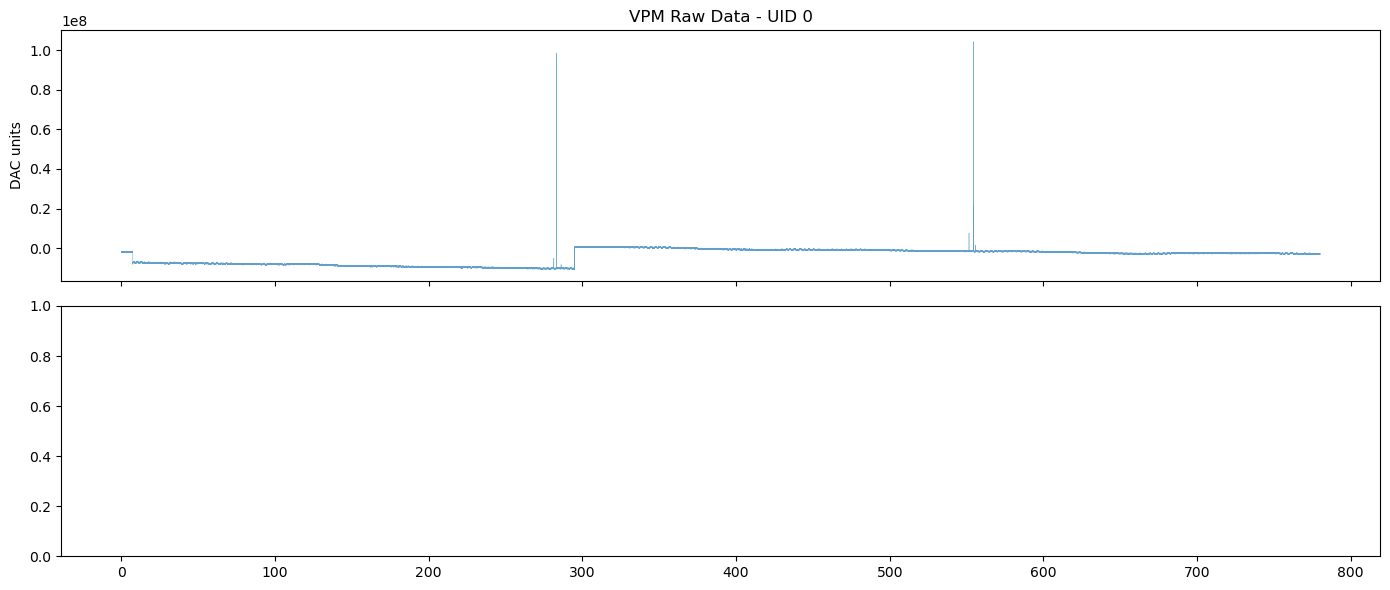

In [6]:
# Plot raw detector timestreams
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# VPM raw data
t_vpm = (vpm_span.tod.ctime - vpm_span.tod.ctime[0]) / 60  # minutes
axes[0].plot(t_vpm, vpm_span.tod.data[0], lw=0.3, alpha=0.7)
axes[0].set_ylabel('DAC units')
axes[0].set_title(f'VPM Raw Data - UID {vpm_span.tod.det_uid[0]}')

plt.tight_layout()
plt.show()

## Modulator Encoder

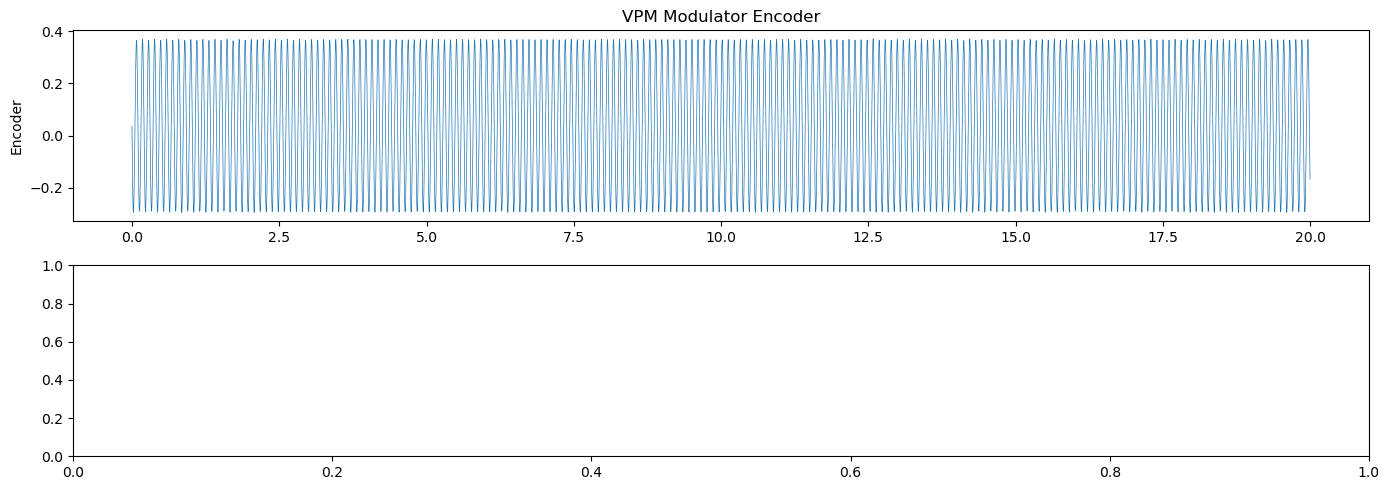

In [7]:
# Plot modulator encoder signal
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

# VPM encoder - show a short segment to see modulation
n_show = 4000  # 20 seconds at 200 Hz
t_short = np.arange(n_show) / 200

axes[0].plot(t_short, vpm_span.tod.mod_enc[:n_show], lw=0.5)
axes[0].set_ylabel('Encoder')
axes[0].set_title('VPM Modulator Encoder')

plt.tight_layout()
plt.show()

## Cuts and Repairs

Before demodulation, we apply cuts and repairs:
- **Relocks**: Detector unlocks that reset the signal
- **Flux jumps**: Discrete jumps in the SQUID feedback
- **Wind gusts**: High atmospheric noise periods
- **RFI**: Radio frequency interference

`pipe.cut_and_fix()` handles these automatically.

In [6]:
# Initialize and apply cuts to both spans
vpm_span.init_cuts()
pipe.cut_and_fix(vpm_span, vpm_span.config, verbose=True)

loading initial cuts
repairing relocks
finding flux jump density
repairing flux jumps
finding missed flux jumps
filling cuts


In [7]:
# Show applied cuts
print("\nCuts applied:")
for name in vpm_span.cut_order:
    print(f"  - {name}")


Cuts applied:
  - DataValidCut_1FramePreExpand
  - ConstDetCut
  - Cryo
  - CMBObsCut
  - MoonDist1_3Deg
  - SunDist20Deg
  - G_ModulatorOnCut
  - PWVCrit5mm_interp4_keep
  - PartPkgConst_gap3_len25
  - RelockWin400
  - UnlockedCut2
  - FluxJumpNpad0
  - VenusDist1_3Deg
  - MarsDist1_3Deg
  - JupiterDist1_3Deg
  - SaturnDist1_3Deg
  - ODCut
  - BadPkgs
  - FjDensity
  - FjRepaired
  - MissedFj


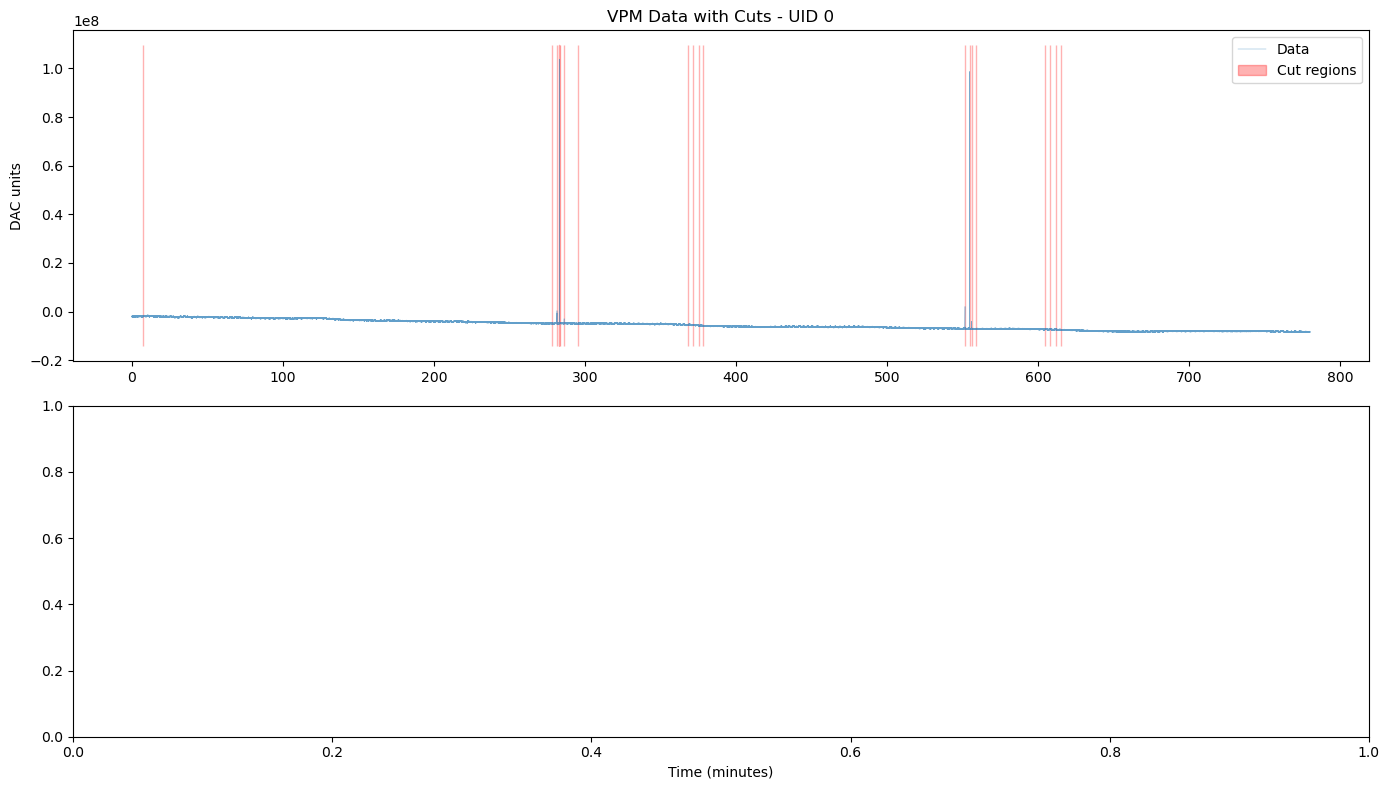

VPM fraction cut for UID 0: 0.1%


In [10]:
# Visualize cuts for both VPM and HWP
det_idx = 0

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# VPM cuts
uid_vpm = vpm_span.tod.det_uid[det_idx]
t_vpm = (vpm_span.tod.ctime - vpm_span.tod.ctime[0]) / 60
axes[0].plot(t_vpm, vpm_span.tod.data[det_idx], lw=0.3, alpha=0.7, label='Data')
cut_mask_vpm = vpm_span.cuts.get_mask()[det_idx]
axes[0].fill_between(t_vpm, axes[0].get_ylim()[0], axes[0].get_ylim()[1], 
                     where=cut_mask_vpm, alpha=0.3, color='red', label='Cut regions')
axes[0].set_ylabel('DAC units')
axes[0].set_title(f'VPM Data with Cuts - UID {uid_vpm}')
axes[0].legend(loc='upper right')

axes[1].set_xlabel('Time (minutes)')

plt.tight_layout()
plt.show()

print(f"VPM fraction cut for UID {uid_vpm}: {cut_mask_vpm.sum() / len(cut_mask_vpm):.1%}")

## Filtering and Demodulation

`pipe.process_span()` applies the core demodulation pipeline:

1. **Calibration**: Convert DAQ units to physical units
2. **Conditioning filters**: Remove readout effects, apply time constant correction
3. **Pair combining**: Combine detector pairs (if configured)
4. **Apply Set 2 Cuts**: Database-driven quality cuts applied here
   - VPMTemplateAmplitudeOutlierCut: Cuts packages with outlier VPM amplitudes
   - VPMTemplateQualityConditionCut: Cuts packages with poor template fit quality
   - VPMAnomalousDayCut: Cuts spans where common-mode removal failed
5. **Demodulation**: Extract Stokes parameters using transfer functions
6. **Downsampling**: Reduce sample rate for map-making

Note: Apply Set 2 cuts require external VPM template database files.

In [8]:
repkg.Span.set_scan_speed(vpm_span)

In [9]:
print("All input data NaN:", np.isnan(vpm_span.tod.data).all())
print("Input data shape:", vpm_span.tod.data.shape)
print("Input data min/max:", np.nanmin(vpm_span.tod.data), np.nanmax(vpm_span.tod.data))

All input data NaN: False
Input data shape: (206, 9496600)
Input data min/max: -22623400.0 121864130.0


In [10]:
print("Detector statuses:", np.unique(vpm_span.tod.info.array_data['det_status']))
print("Number of OD detectors:", np.sum(vpm_span.tod.info.array_data['det_status'] == 'OD'))

Detector statuses: ['OD' 'OFF']
Number of OD detectors: 202


In [11]:
if hasattr(vpm_span, 'cuts'):
    print("Number of detectors:", len(vpm_span.cuts.cuts))
    print("Samples per detector (first):", vpm_span.cuts.cuts[0].nsamps)
    total_masked = sum(cut.get_mask().sum() for cut in vpm_span.cuts.cuts)
    print("Total masked samples (all dets):", total_masked)

Number of detectors: 206
Samples per detector (first): 9496600
Total masked samples (all dets): 39664541


In [12]:
# Show apply_set2 cuts that will be applied during process_span
if hasattr(vpm_cfg, 'apply_set2') and vpm_cfg.apply_set2:
    print("Apply Set 2 cuts configured in VPM config:")
    for cut in vpm_cfg.apply_set2:
        if isinstance(cut, dict):
            cut_name = list(cut.keys())[0]
            print(f"  - {cut_name}")
        else:
            print(f"  - {cut.__class__.__name__}")
    
    print("\nThese cuts use the VPM template database to identify bad packages.")
    print("They will be applied automatically during process_span() at step 4.")
else:
    print("No apply_set2 cuts configured in VPM config")

Apply Set 2 cuts configured in VPM config:
  - VSSAmpTolCut

These cuts use the VPM template database to identify bad packages.
They will be applied automatically during process_span() at step 4.


In [13]:
# Process both VPM and HWP spans

# VPM
print("Processing VPM span...")
repkg.Span.set_scan_speed(vpm_span)
print(f"  scan_type: {vpm_span.scan_type}, speed_ind: {vpm_span.speed_ind}")
pipe.process_span(vpm_span, verbose=True)
print("VPM Done!\n")

Processing VPM span...
  scan_type: azscan, speed_ind: 1
calibrating tod
apply low pass filter for temp
applying initial filter
demodulating data
down sampling time, az, alt, and bs coords
VPM Done!



In [14]:
# Detailed analysis of apply_set2 cuts
print("=" * 70)
print("APPLY_SET2 CUT ANALYSIS")
print("=" * 70)
print()

print(f"Span has {len(vpm_span.det_uid)} detectors total")
print()

# Check for VPM template cuts in the cut_order
vpm_cut_names = ['VPMTemplateAmplitudeOutlierCut', 'VPMTemplateQualityConditionCut', 'VPMAnomalousDayCut']
found_vpm_cuts = [name for name in vpm_span.cut_order if any(vpm_name in name for vpm_name in vpm_cut_names)]

if found_vpm_cuts:
    print("VPM template cuts applied:")
    for cut_name in found_vpm_cuts:
        print(f"  - {cut_name}")
    print()
    
    # Show cut statistics
    print("Cut statistics:")
    for cut_name in found_vpm_cuts:
        if cut_name in vpm_span.cut_dict:
            cut_obj = vpm_span.cut_dict[cut_name]
            if hasattr(cut_obj, 'get_mask'):
                mask = cut_obj.get_mask()
                
                # Count detectors and packages with cuts
                if mask.ndim == 2:
                    dets_with_cuts = sum(1 for i in range(mask.shape[0]) if mask[i].any())
                    total_frac = mask.sum() / mask.size
                    print(f"\n  {cut_name}:")
                    print(f"    Detectors with cuts: {dets_with_cuts}/{mask.shape[0]}")
                    print(f"    Overall cut fraction: {total_frac:.1%}")
                    
                    # Show which detectors are affected
                    if dets_with_cuts > 0 and dets_with_cuts < 15:  # Only if reasonable number
                        affected_uids = [vpm_span.det_uid[i] for i in range(mask.shape[0]) if mask[i].any()]
                        print(f"    Affected UIDs: {affected_uids}")
                else:
                    frac = mask.sum() / len(mask)
                    print(f"  {cut_name}: {frac:.1%} of samples cut")
    
    print()
    print("=" * 70)
    print("WHAT EACH CUT DOES:")
    print("=" * 70)
    print()
    print("VPMTemplateAmplitudeOutlierCut:")
    print("  - Finds packages where CM-removed amplitude is an outlier")
    print("  - Uses IQR (interquartile range) method with factor 1.5")
    print("  - Only analyzes detectors with quality >= 0.5")
    print()
    print("VPMTemplateQualityConditionCut:")
    print("  - Cuts packages with poor template fit quality (quality < 0.5)")
    print("  - Cuts packages with missing/NULL amplitude values")
    print("  - Analyzes ALL detectors in database (not just high-quality ones)")
    print()
    print("VPMAnomalousDayCut:")
    print("  - Cuts entire spans where CM removal failed")
    print("  - Identifies spans with |median(CM-removed)| > 0.0005")
    print("  - Indicates systematic issues requiring investigation")
else:
    print("No VPM template cuts were applied.")
    print("Timeline may be outside database coverage.")

APPLY_SET2 CUT ANALYSIS

Span has 206 detectors total

No VPM template cuts were applied.
Timeline may be outside database coverage.


In [15]:
# Check demodulated output for both
print("VPM demodulated:")
print(f"  Shape: {vpm_span.u.shape}")
print(f"  Downsampled from {vpm_span.tod.nsamps:,} to {vpm_span.u.shape[1]:,} samples (factor {vpm_span.tod.nsamps // vpm_span.u.shape[1]})")

# print("\nHWP demodulated:")
# print(f"  Shape: {hwp_span.u.shape}")
# print(f"  Downsampled from {hwp_span.tod.nsamps:,} to {hwp_span.u.shape[1]:,} samples (factor {hwp_span.tod.nsamps // hwp_span.u.shape[1]})")

VPM demodulated:
  Shape: (206, 118708)
  Downsampled from 9,496,600 to 118,708 samples (factor 79)


## Demodulated Stokes Parameters

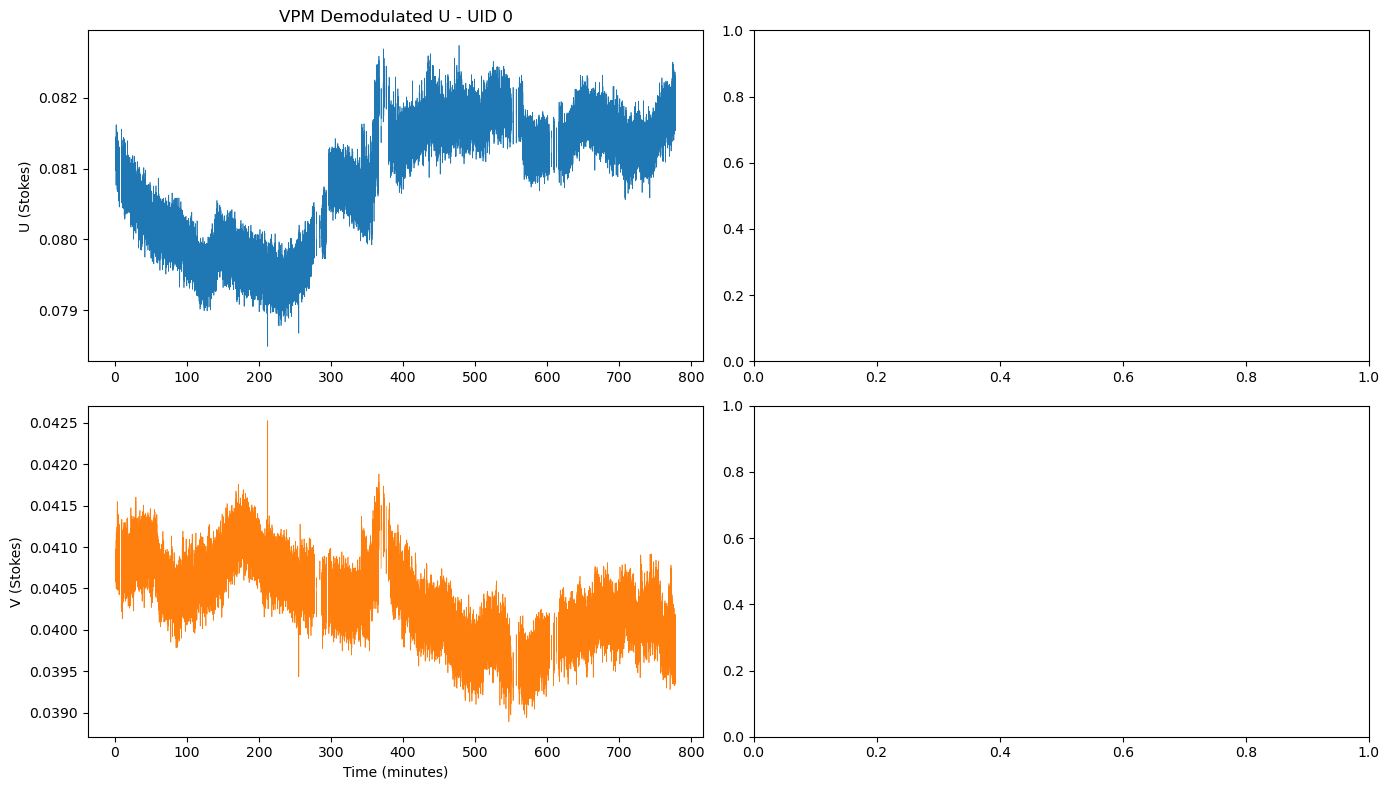

In [18]:
# Plot demodulated Stokes parameters (masking cut samples)
# VPM: U/V (circular polarization), HWP: Q/U (linear polarization)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
det_idx = 0

# Get downsampled cut masks (True = cut)
vpm_mask = vpm_span.cuts.cuts[det_idx].get_mask()
# hwp_mask = hwp_span.cuts.cuts[det_idx].get_mask()

# VPM - U and V (circular)
t_vpm_ds = (vpm_span.ds_time - vpm_span.ds_time[0]) / 60
vpm_u_masked = np.where(vpm_mask, np.nan, vpm_span.u[det_idx])
vpm_v_masked = np.where(vpm_mask, np.nan, vpm_span.v[det_idx])

axes[0, 0].plot(t_vpm_ds, vpm_u_masked, lw=0.5)
axes[0, 0].set_ylabel('U (Stokes)')
axes[0, 0].set_title(f'VPM Demodulated U - UID {vpm_span.tod.det_uid[det_idx]}')

axes[1, 0].plot(t_vpm_ds, vpm_v_masked, lw=0.5, color='C1')
axes[1, 0].set_ylabel('V (Stokes)')
axes[1, 0].set_xlabel('Time (minutes)')

# # HWP - Q and U (linear)
# t_hwp_ds = (hwp_span.ds_time - hwp_span.ds_time[0]) / 60
# hwp_q_masked = np.where(hwp_mask, np.nan, hwp_span.q[det_idx])
# hwp_u_masked = np.where(hwp_mask, np.nan, hwp_span.u[det_idx])

# axes[0, 1].plot(t_hwp_ds, hwp_q_masked, lw=0.5, color='C2')
# axes[0, 1].set_ylabel('Q (Stokes)')
# axes[0, 1].set_title(f'HWP Demodulated Q - UID {hwp_span.tod.det_uid[det_idx]}')

# axes[1, 1].plot(t_hwp_ds, hwp_u_masked, lw=0.5, color='C3')
# axes[1, 1].set_ylabel('U (Stokes)')
# axes[1, 1].set_xlabel('Time (minutes)')

plt.tight_layout()
plt.show()

## Power Spectra Comparison

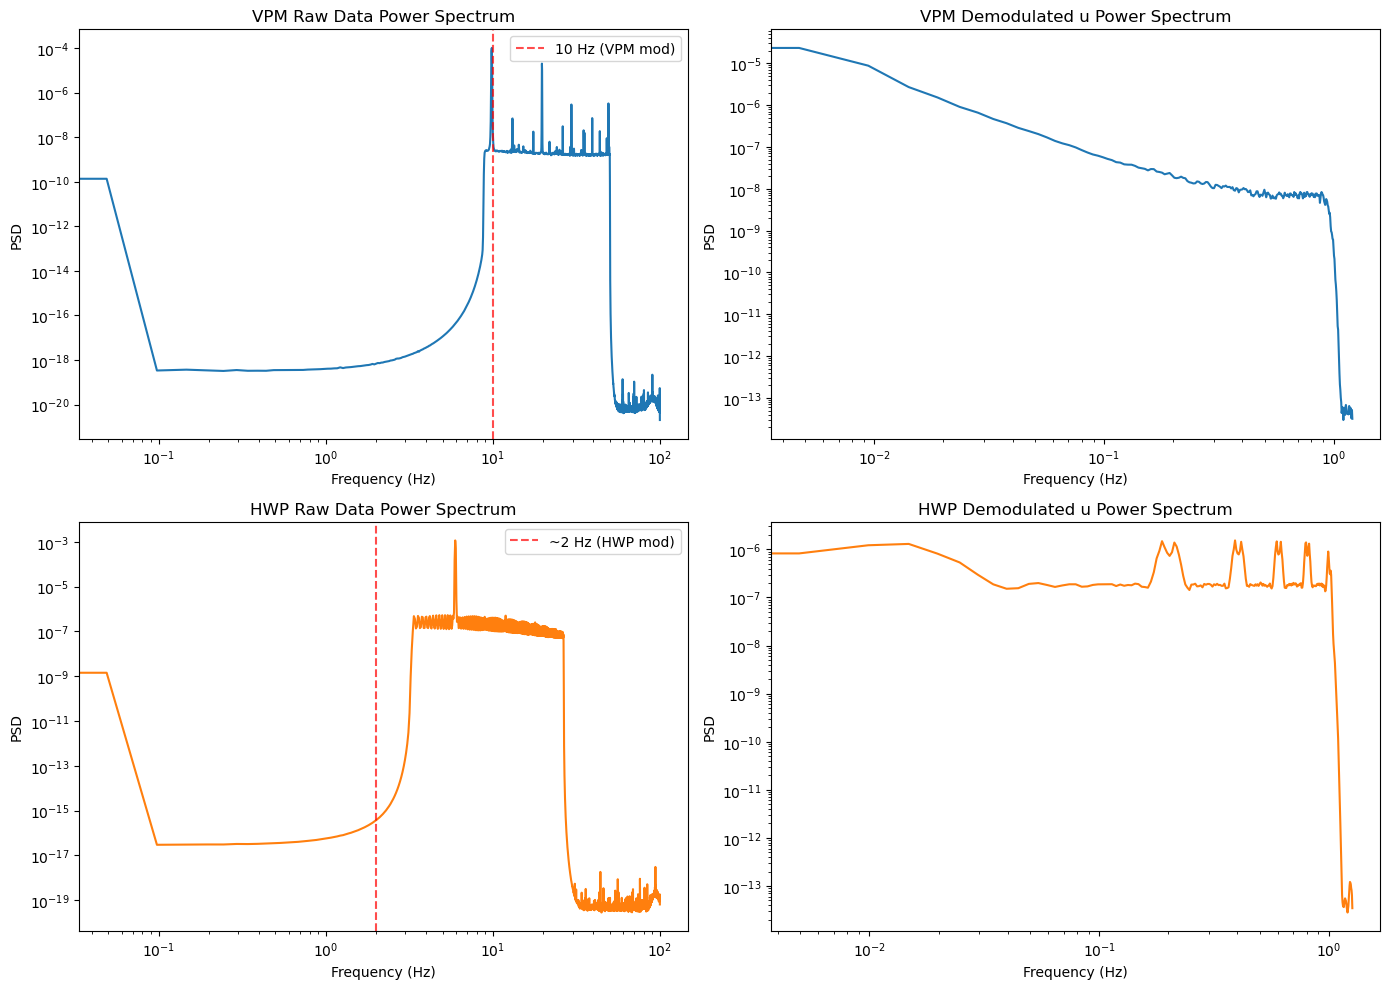

In [18]:
# Compare power spectra: raw vs demodulated for VPM and HWP
from scipy import signal

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fs_raw = 200  # Hz
nperseg = 4096

# VPM Raw
f_raw, psd_raw_vpm = signal.welch(vpm_span.tod.data[0], fs=fs_raw, nperseg=nperseg)
axes[0, 0].loglog(f_raw, psd_raw_vpm)
axes[0, 0].set_xlabel('Frequency (Hz)')
axes[0, 0].set_ylabel('PSD')
axes[0, 0].set_title('VPM Raw Data Power Spectrum')
axes[0, 0].axvline(10, color='r', ls='--', alpha=0.7, label='10 Hz (VPM mod)')
axes[0, 0].legend()

# VPM Demodulated
fs_ds_vpm = fs_raw / (vpm_span.tod.nsamps // vpm_span.u.shape[1])
f_ds, psd_u_vpm = signal.welch(vpm_span.u[0], fs=fs_ds_vpm, nperseg=min(512, len(vpm_span.u[0])//4))
axes[0, 1].loglog(f_ds, psd_u_vpm)
axes[0, 1].set_xlabel('Frequency (Hz)')
axes[0, 1].set_ylabel('PSD')
axes[0, 1].set_title('VPM Demodulated u Power Spectrum')

# HWP Raw
f_raw, psd_raw_hwp = signal.welch(hwp_span.tod.data[0], fs=fs_raw, nperseg=nperseg)
axes[1, 0].loglog(f_raw, psd_raw_hwp, color='C1')
axes[1, 0].set_xlabel('Frequency (Hz)')
axes[1, 0].set_ylabel('PSD')
axes[1, 0].set_title('HWP Raw Data Power Spectrum')
axes[1, 0].axvline(2, color='r', ls='--', alpha=0.7, label='~2 Hz (HWP mod)')
axes[1, 0].legend()

# HWP Demodulated
fs_ds_hwp = fs_raw / (hwp_span.tod.nsamps // hwp_span.u.shape[1])
f_ds, psd_u_hwp = signal.welch(hwp_span.u[0], fs=fs_ds_hwp, nperseg=min(512, len(hwp_span.u[0])//4))
axes[1, 1].loglog(f_ds, psd_u_hwp, color='C1')
axes[1, 1].set_xlabel('Frequency (Hz)')
axes[1, 1].set_ylabel('PSD')
axes[1, 1].set_title('HWP Demodulated u Power Spectrum')

plt.tight_layout()
plt.show()

## Pointing and Scanning

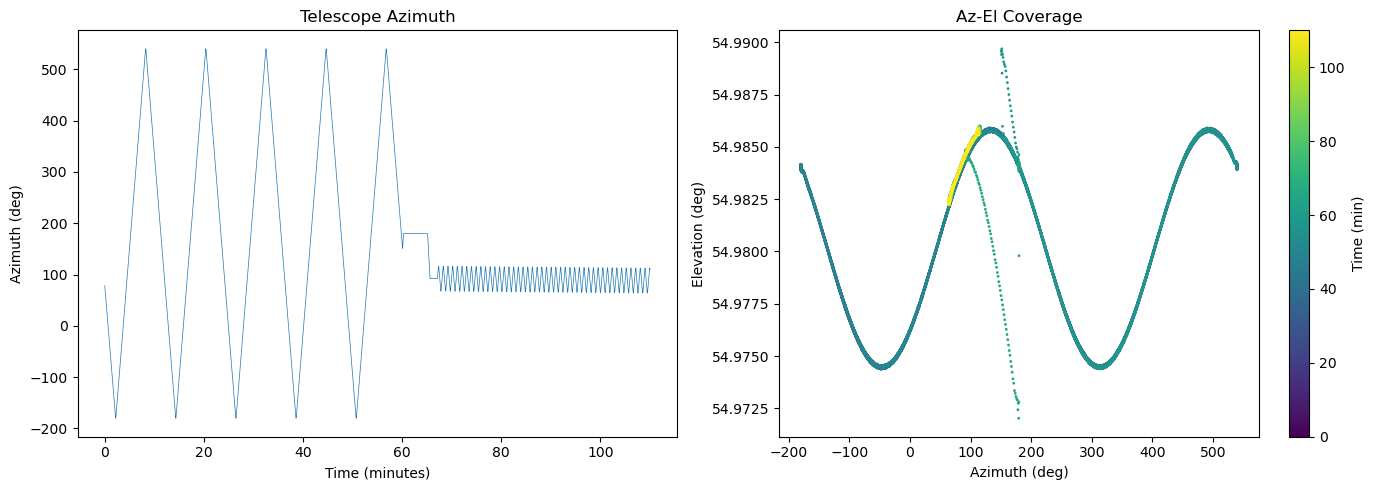

In [30]:
# Show telescope pointing during observation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Azimuth vs time
t_ds = (vpm_span.ds_time - vpm_span.ds_time[0]) / 60
axes[0].plot(t_ds, np.rad2deg(vpm_span.ds_az), lw=0.5)
axes[0].set_xlabel('Time (minutes)')
axes[0].set_ylabel('Azimuth (deg)')
axes[0].set_title('Telescope Azimuth')

# Az-El coverage
axes[1].scatter(np.rad2deg(vpm_span.ds_az), np.rad2deg(vpm_span.ds_alt), 
                c=t_ds, s=1, cmap='viridis')
axes[1].set_xlabel('Azimuth (deg)')
axes[1].set_ylabel('Elevation (deg)')
axes[1].set_title('Az-El Coverage')
plt.colorbar(axes[1].collections[0], ax=axes[1], label='Time (min)')

plt.tight_layout()
plt.show()

## Summary

This notebook demonstrated the Dpipe workflow:

1. **Config loading**: `startup.DpipeConfig` reads YAML files with pipeline settings
2. **Span construction**: `repkg.Span(t0, t1, config)` builds a span from a time range
3. **Data loading**: `span.load_tod()` reads raw data from DataPkgs
4. **Cuts**: `span.init_cuts()` + `pipe.cut_and_fix()` apply quality cuts
5. **Processing**: `pipe.process_span()` runs filtering and demodulation
6. **Output**: Demodulated Stokes parameters in `span.u`, `span.v`

### Key Classes
- **`Span`**: Container for span data, cuts, and demodulated output
- **`DpipeConfig`**: Pipeline configuration from YAML files
- **`LoadPtod`**: For loading already-processed spans from disk

### For production runs
Use `scripts/dpipe.py` with MPI:
```bash
mpirun -n 12 python -m mpi4py scripts/dpipe.py parameter_files/w1_example.yml -gmi
```